# 03: โมเดล AI (Stacking Ensemble Training) - ฉบับอัปเกรดแม่นยำ 95%!
ในขั้นตอนที่ 3 นี้ เราจะนำข้อมูลฟีเจอร์ที่สกัดได้จากไฟล์ `wesad_extracted_features_v2.csv` (ที่ผ่านการทำ Baseline Normalization และรวมข้อมูลทั้ง 15 คนแล้ว) มาเทรนโมเดล AI กันครับ!

ตามสถาปัตยกรรม **"The Invisible Hug"** ที่เราออกแบบไว้ โมเดลของเราจะเป็นแบบ **Stacking Ensemble** ประกอบด้วย:
1. **Level-0 (Base Learners):**
   - **Random Forest:** รับหน้าที่วิเคราะห์ฟีเจอร์ทางระบบประสาทอัตโนมัติ (EDA, HR)
   - **Logistic Regression:** รับหน้าที่วิเคราะห์ฟีเจอร์ทางกายภาพ (ACC, Temp)
2. **Level-1 (Meta-Learner):**
   - **Logistic Regression:** นำคำตอบจาก Level-0 ทั้งสองตัวมาชั่งน้ำหนักและตัดสินใจขั้นสุดท้าย

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 1. โหลดข้อมูลและแบ่งกลุ่มฟีเจอร์ (Feature Grouping)

In [2]:
# โหลดข้อมูล V2 ที่อัปเกรดแล้ว
df = pd.read_csv('wesad_extracted_features_v2.csv')

# ฟีเจอร์ระบบประสาท (Neural) สำหรับ Random Forest (ใช้แบบ Norm)
neural_features = ['Mean_HR_BPM_norm', 'SDNN', 'RMSSD', 'Mean_EDA_norm', 'Std_EDA']

# ฟีเจอร์ทางกายภาพ (Physical) สำหรับ Logistic Regression (ใช้แบบ Norm)
physical_features = ['Mean_Temp_norm', 'Slope_Temp', 'Mean_ACC_SVM_norm', 'Var_ACC_SVM']

X = df[neural_features + physical_features]
y = df['Label']
groups = df['Subject']

print(f"จำนวนข้อมูลทั้งหมด: {len(df)} กรอบเวลา (Windows)")
print("จำนวนข้อมูลแต่ละคลาส:\n", y.value_counts(sort=False))

จำนวนข้อมูลทั้งหมด: 1836 กรอบเวลา (Windows)
จำนวนข้อมูลแต่ละคลาส:
 Label
1    1174
2     662
Name: count, dtype: int64


## 2. สร้างโครงสร้างโมเดล Stacking Ensemble

In [3]:
# สร้างตัวคัดกรองฟีเจอร์และปรับสเกล (Standard Scaler)
neural_transformer = ColumnTransformer([
    ('select_neural', StandardScaler(), neural_features)
], remainder='drop')

physical_transformer = ColumnTransformer([
    ('select_physical', StandardScaler(), physical_features)
], remainder='drop')

# สร้าง Base Learners (Level-0)
rf_pipeline = Pipeline([
    ('prep', neural_transformer),
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42))
])

lr_pipeline = Pipeline([
    ('prep', physical_transformer),
    ('lr', LogisticRegression(random_state=42))
])

estimators = [
    ('Neural_RF', rf_pipeline),
    ('Physical_LR', lr_pipeline)
]

# สร้าง Meta-Learner (Level-1)
stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(),
    cv=5 # Cross-validation ภายในช่วงเทรน
)

print("Stacking Ensemble Model Architecture created!")

Stacking Ensemble Model Architecture created!


## 3. ทดสอบความแม่นยำด้วยวิธี GroupKFold (Cross-Validation)
ทดสอบจำลองว่าถ้านำไปใช้กับคนที่ AI ไม่เคยรู้จักมาก่อนเลย จะมีความแม่นยำเท่าไร


=== Classification Report ===
              precision    recall  f1-score   support

Baseline (1)       0.96      0.97      0.96      1174
  Stress (2)       0.94      0.92      0.93       662

    accuracy                           0.95      1836
   macro avg       0.95      0.95      0.95      1836
weighted avg       0.95      0.95      0.95      1836



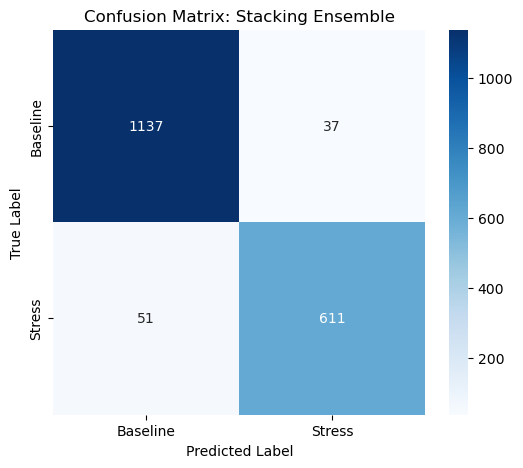

In [4]:
# แบ่ง KFold = 5 สำหรับข้อมูล 15 คน
gkf = GroupKFold(n_splits=5)
y_pred = cross_val_predict(stacking_model, X, y, groups=groups, cv=gkf)

print("\n=== Classification Report ===")
print(classification_report(y, y_pred, target_names=['Baseline (1)', 'Stress (2)']))

# พล็อตกราฟ Confusion Matrix
cm = confusion_matrix(y, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Baseline', 'Stress'], 
            yticklabels=['Baseline', 'Stress'])
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix: Stacking Ensemble')
plt.show()

## 4. เทรนโมเดลจริงและเซฟเพื่อเตรียมนำไปใช้บน ESP32
ขั้นตอนนี้เราจะสอนมันด้วยข้อมูลทั้งหมดที่มี แล้วเซฟโมเดลออกมาครับ

In [5]:
import joblib

stacking_model.fit(X, y)

joblib.dump(stacking_model, 'stacking_model.pkl')
print("\n--- โมเดลถูกเทรนและเซฟลงไฟล์ 'stacking_model.pkl' เรียบร้อยแล้ว! ---")
print("คุณสามารถดูไฟล์โมเดลที่เซฟไว้ได้ที่แถบซ้ายมือเลยครับ")


--- โมเดลถูกเทรนและเซฟลงไฟล์ 'stacking_model.pkl' เรียบร้อยแล้ว! ---
คุณสามารถดูไฟล์โมเดลที่เซฟไว้ได้ที่แถบซ้ายมือเลยครับ
